In [ ]:
# Library
import os
import random
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from google.colab import drive
from skimage.metrics import structural_similarity
from torch.utils.data import ConcatDataset, DataLoader, random_split
from torchvision import datasets, transforms

SEED = 42
BATCH_SIZE = 128
LATENT_DIM = 64
LEARNING_RATE = 0.001
EPOCHS = 20
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print("Device:", DEVICE)

if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))


Device: cuda
GPU: Tesla T4


In [1]:
# CP

from pathlib import Path

USE_GOOGLE_DRIVE = True

if USE_GOOGLE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")

    PROJECT_DIR = Path(
        "/content/drive/MyDrive/Model_Comparison"
    )
else:
    PROJECT_DIR = Path(".")

CHECKPOINT_DIR = PROJECT_DIR / "checkpoints"
OUTPUT_DIR = PROJECT_DIR / "outputs" / "sparse_ae"

CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Use Google Drive:", USE_GOOGLE_DRIVE)
print("Project Directory:", PROJECT_DIR)
print("Checkpoint Directory:", CHECKPOINT_DIR)
print("Output Directory:", OUTPUT_DIR)


Mounted at /content/drive
Use Google Drive: True
Project Directory: /content/drive/MyDrive/Model_Comparison
Checkpoint Directory: /content/drive/MyDrive/Model_Comparison/checkpoints
Output Directory: /content/drive/MyDrive/Model_Comparison/outputs/sparse_ae


In [ ]:
# Dataset
transform = transforms.ToTensor()

train_original = datasets.FashionMNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_original = datasets.FashionMNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

full_dataset = ConcatDataset([
    train_original,
    test_original
])

train_dataset, val_dataset, test_dataset = random_split(
    full_dataset,
    [56000, 7000, 7000],
    generator=torch.Generator().manual_seed(SEED)
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("Total Dataset:", len(full_dataset))
print("Training Set:", len(train_dataset))
print("Validation Set:", len(val_dataset))
print("Testing Set:", len(test_dataset))


100%|██████████| 26.4M/26.4M [00:02<00:00, 12.7MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 202kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.79MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 23.4MB/s]

Total Dataset: 70000
Training Set: 56000
Validation Set: 7000
Testing Set: 7000


In [ ]:
# Sparse AE -> Architecture

class SparseAE(nn.Module):
    def __init__(self, latent_dim=64):
        super().__init__()

        self.encoder = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 256),
            nn.ReLU(),
            nn.Linear(256, latent_dim),
            nn.ReLU()
        )

        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 256),
            nn.ReLU(),
            nn.Linear(256, 784),
            nn.Sigmoid()
        )

    def forward(self, x):
        z = self.encoder(x)
        reconstructed = self.decoder(z)

        return reconstructed.view(-1, 1, 28, 28), z


sparse_ae = SparseAE(
    latent_dim=LATENT_DIM
).to(DEVICE)

print(sparse_ae)


SparseAE(
  (encoder): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=256, bias=True)
    (2): ReLU()
    (3): Linear(in_features=256, out_features=64, bias=True)
    (4): ReLU()
  )
  (decoder): Sequential(
    (0): Linear(in_features=64, out_features=256, bias=True)
    (1): ReLU()
    (2): Linear(in_features=256, out_features=784, bias=True)
    (3): Sigmoid()
  )
)


In [ ]:
# Sparse AE -> Training

SPARSITY_LAMBDA = 0.0001

optimizer_sparse = optim.Adam(
    sparse_ae.parameters(),
    lr=LEARNING_RATE
)

criterion_sparse = nn.MSELoss()

sparse_train_losses = []
sparse_val_losses = []
sparse_epoch_times = []
sparse_penalties = []

best_sparse_val_loss = float("inf")
best_sparse_ae_state = None

for epoch in range(EPOCHS):

    start_time = time.perf_counter()
    sparse_ae.train()

    total_recon_loss = 0.0
    total_sparse_penalty = 0.0

    for images, _ in train_loader:

        images = images.to(DEVICE)

        optimizer_sparse.zero_grad()

        reconstructed, z = sparse_ae(images)

        recon_loss = criterion_sparse(
            reconstructed,
            images
        )

        sparsity_loss = z.abs().sum(dim=1).mean()

        total_loss = (
            recon_loss +
            SPARSITY_LAMBDA * sparsity_loss
        )

        total_loss.backward()
        optimizer_sparse.step()

        batch_size = images.size(0)

        total_recon_loss += recon_loss.item() * batch_size
        total_sparse_penalty += sparsity_loss.item() * batch_size

    avg_recon_loss = total_recon_loss / len(train_dataset)
    avg_sparse_penalty = total_sparse_penalty / len(train_dataset)

    sparse_ae.eval()
    total_val_loss = 0.0

    with torch.no_grad():

        for images, _ in val_loader:

            images = images.to(DEVICE)

            reconstructed, z = sparse_ae(images)

            loss = criterion_sparse(
                reconstructed,
                images
            )

            total_val_loss += loss.item() * images.size(0)

    avg_val_loss = total_val_loss / len(val_dataset)

    if DEVICE.type == "cuda":
        torch.cuda.synchronize()

    epoch_time = time.perf_counter() - start_time

    sparse_train_losses.append(avg_recon_loss)
    sparse_val_losses.append(avg_val_loss)
    sparse_epoch_times.append(epoch_time)
    sparse_penalties.append(avg_sparse_penalty)

    if avg_val_loss < best_sparse_val_loss:
        best_sparse_val_loss = avg_val_loss
        best_sparse_ae_state = {
            key: value.detach().cpu().clone()
            for key, value in sparse_ae.state_dict().items()
        }

    print(
        f"Epoch [{epoch+1}/{EPOCHS}] | "
        f"Train MSE: {avg_recon_loss:.6f} | "
        f"Val MSE: {avg_val_loss:.6f} | "
        f"L1: {avg_sparse_penalty:.4f} | "
        f"Time: {epoch_time:.2f}s"
    )

sparse_ae.load_state_dict(best_sparse_ae_state)

print("\nSparse AE Training Complete!")
print(f"Best Validation MSE: {best_sparse_val_loss:.6f}")
print(f"Average Epoch Time: {np.mean(sparse_epoch_times):.2f}s")
print(f"Sparsity Lambda: {SPARSITY_LAMBDA}")

# Save model checkpoint
checkpoint_path = CHECKPOINT_DIR / "sparse_ae.pt"

torch.save(
    best_sparse_ae_state,
    checkpoint_path
)

print("Saved checkpoint:", checkpoint_path)

# Save training history
pd.DataFrame({
    "epoch": range(1, EPOCHS + 1),
    "train_mse": sparse_train_losses,
    "val_mse": sparse_val_losses,
    "sparsity_penalty": sparse_penalties,
    "epoch_time_s": sparse_epoch_times
}).to_csv(
    OUTPUT_DIR / "loss_history.csv",
    index=False
)


Epoch [1/20] | Train MSE: 0.035377 | Val MSE: 0.020669 | L1: 26.1934 | Time: 8.31s
Epoch [2/20] | Train MSE: 0.018254 | Val MSE: 0.016848 | L1: 16.6079 | Time: 7.54s
Epoch [3/20] | Train MSE: 0.015625 | Val MSE: 0.014975 | L1: 15.0369 | Time: 8.11s
Epoch [4/20] | Train MSE: 0.014194 | Val MSE: 0.013988 | L1: 14.3498 | Time: 8.21s
Epoch [5/20] | Train MSE: 0.013283 | Val MSE: 0.013199 | L1: 13.7703 | Time: 8.03s
Epoch [6/20] | Train MSE: 0.012638 | Val MSE: 0.012581 | L1: 13.2874 | Time: 7.41s
Epoch [7/20] | Train MSE: 0.012101 | Val MSE: 0.012108 | L1: 12.8892 | Time: 8.02s
Epoch [8/20] | Train MSE: 0.011690 | Val MSE: 0.011767 | L1: 12.5212 | Time: 7.99s
Epoch [9/20] | Train MSE: 0.011368 | Val MSE: 0.011536 | L1: 12.0926 | Time: 7.46s
Epoch [10/20] | Train MSE: 0.011101 | Val MSE: 0.011352 | L1: 11.7012 | Time: 8.10s
Epoch [11/20] | Train MSE: 0.010879 | Val MSE: 0.011013 | L1: 11.3625 | Time: 7.12s
Epoch [12/20] | Train MSE: 0.010631 | Val MSE: 0.010917 | L1: 11.0930 | Time: 8.10s
E

In [ ]:
# Sparse AE -> Test Evaluation

sparse_ae.eval()

total_squared_error = 0.0
total_pixels = 0

psnr_values = []
ssim_values = []

zero_count = 0
total_latent_values = 0

with torch.no_grad():

    for images, _ in test_loader:

        images = images.to(DEVICE)

        reconstructed, z = sparse_ae(images)

        squared_error = (reconstructed - images) ** 2

        total_squared_error += squared_error.sum().item()
        total_pixels += images.numel()

        mse_per_image = squared_error.mean(dim=(1, 2, 3))

        psnr_batch = 10 * torch.log10(
            1.0 / mse_per_image.clamp_min(1e-10)
        )

        psnr_values.extend(
            psnr_batch.cpu().numpy()
        )

        original_np = images.cpu().numpy()
        reconstructed_np = reconstructed.cpu().numpy()

        for i in range(len(images)):

            score = structural_similarity(
                original_np[i, 0],
                reconstructed_np[i, 0],
                data_range=1.0
            )

            ssim_values.append(score)

        zero_count += (z.abs() < 1e-6).sum().item()
        total_latent_values += z.numel()

sparse_test_mse = total_squared_error / total_pixels
sparse_test_psnr = float(np.mean(psnr_values))
sparse_test_ssim = float(np.mean(ssim_values))

sparsity_ratio = (
    zero_count / total_latent_values
) * 100

print("Sparse AE Test Results")
print(f"Test MSE       : {sparse_test_mse:.6f}")
print(f"Test PSNR      : {sparse_test_psnr:.4f}")
print(f"Test SSIM      : {sparse_test_ssim:.6f}")
print(f"Sparsity Ratio : {sparsity_ratio:.2f}%")

pd.DataFrame([{
    "model": "Sparse AE",
    "test_mse": sparse_test_mse,
    "test_psnr": sparse_test_psnr,
    "test_ssim": sparse_test_ssim,
    "sparsity_ratio": sparsity_ratio,
    "best_val_loss": best_sparse_val_loss,
    "mean_epoch_time_s": float(np.mean(sparse_epoch_times)),
    "latent_dim": LATENT_DIM,
    "sparsity_lambda": SPARSITY_LAMBDA,
    "epochs": EPOCHS,
    "seed": SEED
}]).to_csv(
    OUTPUT_DIR / "test_metrics.csv",
    index=False
)


Sparse AE Test Results
Test MSE       : 0.009742
Test PSNR      : 21.0562
Test SSIM      : 0.759659
Sparsity Ratio : 51.92%


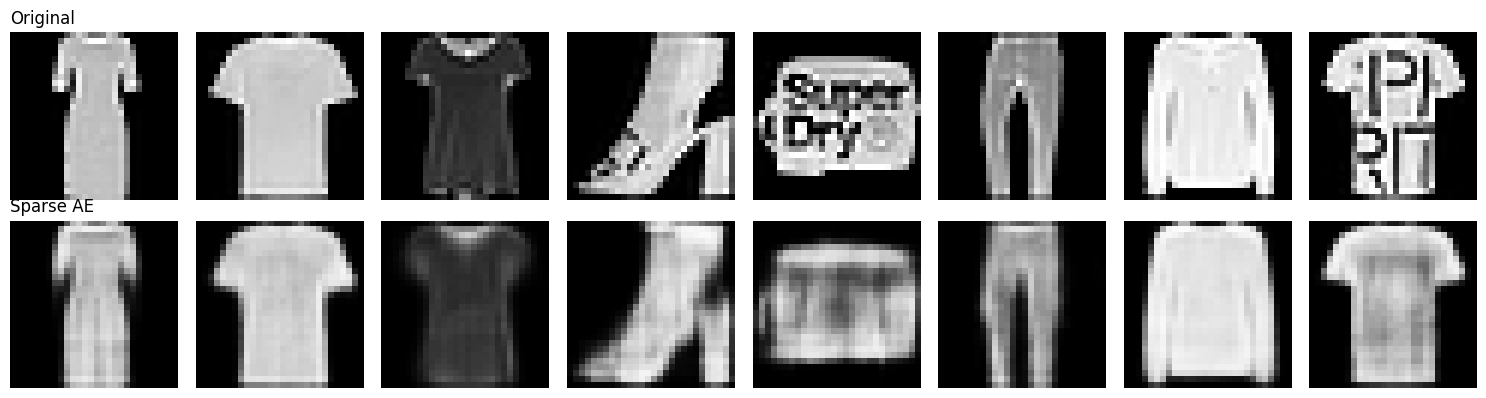

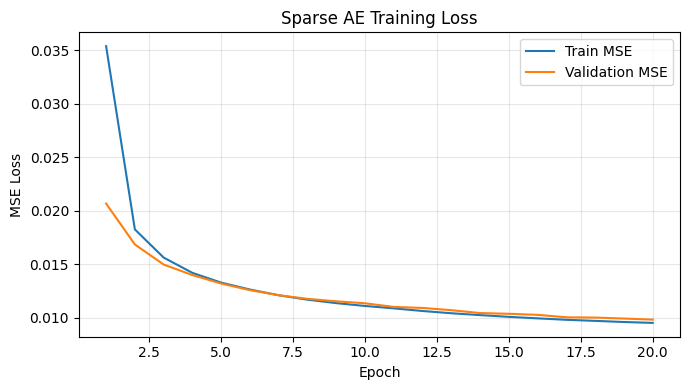

Saved images and CSV files to: /content/drive/MyDrive/Model_Comparison/outputs/sparse_ae


In [ ]:
# Sparse AE -> Reconstruction

sparse_ae.eval()

comparison_images, comparison_labels = next(iter(test_loader))
comparison_images = comparison_images[:8].to(DEVICE)

with torch.no_grad():
    comparison_reconstructed, _ = sparse_ae(comparison_images)

fig, axes = plt.subplots(2, 8, figsize=(15, 4))

for i in range(8):

    axes[0, i].imshow(
        comparison_images[i, 0].cpu(),
        cmap="gray",
        vmin=0,
        vmax=1
    )

    axes[1, i].imshow(
        comparison_reconstructed[i, 0].cpu(),
        cmap="gray",
        vmin=0,
        vmax=1
    )

    for row in range(2):
        axes[row, i].axis("off")

axes[0, 0].set_title("Original", loc="left")
axes[1, 0].set_title("Sparse AE", loc="left")

fig.tight_layout()

fig.savefig(
    OUTPUT_DIR / "reconstruction.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Sparse AE -> Training Loss

fig, ax = plt.subplots(figsize=(7, 4))

ax.plot(
    range(1, EPOCHS + 1),
    sparse_train_losses,
    label="Train MSE"
)

ax.plot(
    range(1, EPOCHS + 1),
    sparse_val_losses,
    label="Validation MSE"
)

ax.set(
    xlabel="Epoch",
    ylabel="MSE Loss",
    title="Sparse AE Training Loss"
)

ax.legend()
ax.grid(alpha=0.3)

fig.tight_layout()

fig.savefig(
    OUTPUT_DIR / "training_loss.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved images and CSV files to:", OUTPUT_DIR)
